In [1]:
%load_ext autoreload
%autoreload 2
import torch
import torch.nn as nn

from collections import defaultdict
from torch.utils.data import DataLoader
from torchvision.models import ResNet50_Weights

from models.create_model import create_resnet50
from datasets.imagenet_mini import ImagenetMini
from semanticlens.component_visualization import aggregators

# ----------------------------
# 1. Load model
# ----------------------------

weights = ResNet50_Weights.IMAGENET1K_V2
transform = weights.transforms()

model = create_resnet50()
model.eval()

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
model = model.to(device)


# ----------------------------
# 2. Load dataset
# ----------------------------

dataset = ImagenetMini(
    wordnet_ids_to_classes_path=(
        "../datasets/input_files/"
        "wordnet_ids_to_classes.txt"
    ),
    transform=transform
)

# First 35 samples
data = [dataset[i] for i in range(35)]

dataloader = DataLoader(
    data,
    batch_size=32,
    shuffle=False,
    num_workers=8
)


# ----------------------------
# 3. Register forward hooks
# ----------------------------

activations = defaultdict(list)
handles = []


def get_activation(name):
    def hook(module, inputs, output):
        activations[name].append(
            output.detach().cpu()
        )
        print(output.shape)
    return hook


for name, module in model.named_modules():
    if isinstance(module, nn.BatchNorm2d):
        handle = module.register_forward_hook(
            get_activation(name)
        )
        handles.append(handle)


# ----------------------------
# 4. Collect activations
# ----------------------------

with torch.no_grad():
    for images, labels in dataloader:

        images = images.to(device)

        outputs = model(images)


# ----------------------------
# 5. Remove hooks
# ----------------------------

for handle in handles:
    handle.remove()


# ----------------------------
# 6. Concatenate batches
# ----------------------------

activations = {
    name: torch.cat(tensors, dim=0)
    for name, tensors in activations.items()
}


# ----------------------------
# 7. Inspect activations
# ----------------------------

for name, activation in activations.items():
    print(name, activation.shape)

Using device: cpu
torch.Size([32, 64, 112, 112])
torch.Size([32, 64, 56, 56])
torch.Size([32, 64, 56, 56])
torch.Size([32, 256, 56, 56])
torch.Size([32, 256, 56, 56])
torch.Size([32, 64, 56, 56])
torch.Size([32, 64, 56, 56])
torch.Size([32, 256, 56, 56])
torch.Size([32, 64, 56, 56])
torch.Size([32, 64, 56, 56])
torch.Size([32, 256, 56, 56])
torch.Size([32, 128, 56, 56])
torch.Size([32, 128, 28, 28])
torch.Size([32, 512, 28, 28])
torch.Size([32, 512, 28, 28])
torch.Size([32, 128, 28, 28])
torch.Size([32, 128, 28, 28])
torch.Size([32, 512, 28, 28])
torch.Size([32, 128, 28, 28])
torch.Size([32, 128, 28, 28])
torch.Size([32, 512, 28, 28])
torch.Size([32, 128, 28, 28])
torch.Size([32, 128, 28, 28])
torch.Size([32, 512, 28, 28])
torch.Size([32, 256, 28, 28])
torch.Size([32, 256, 14, 14])
torch.Size([32, 1024, 14, 14])
torch.Size([32, 1024, 14, 14])
torch.Size([32, 256, 14, 14])
torch.Size([32, 256, 14, 14])
torch.Size([32, 1024, 14, 14])
torch.Size([32, 256, 14, 14])
torch.Size([32, 256, 14,

In [18]:
for name, module in model.named_modules():
    print(name, module)

 ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1,

In [2]:
active_channels = {}
filtered_activations = {}

threshold_type = "percentile"
assert threshold_type in ["positive", "percentile", "mean"]

for name, activation in activations.items():
    # activation: [N, C, H, W]

    # Maximum spatial activation per channel
    channel_scores = activation.amax(dim=(2, 3))  # [N, C]

    # Global 90th percentile across samples and channels
    if threshold_type == "positive":
        threshold = 0.1
    elif threshold_type == "mean":
        threshold = channel_scores.mean()
        print(f"mean threshold: {threshold}")
    else:
        threshold = torch.quantile(
            channel_scores.float().flatten(),
            q=0.10
        )
        print(f"percentile threshold: {threshold}")

    # Active channels
    active_mask = channel_scores > threshold  # [N, C]
    active_channels[name] = active_mask

    # Active for every image
    channel_mask = active_mask.all(dim=0)

    filtered_activations[name] = activation[:, channel_mask]

    print(
        name,
        filtered_activations[name].shape
    )

percentile threshold: 7.754602909088135
bn1 torch.Size([35, 30, 112, 112])
percentile threshold: 2.031548023223877
layer1.0.bn1 torch.Size([35, 39, 56, 56])
percentile threshold: 1.118794322013855
layer1.0.bn2 torch.Size([35, 45, 56, 56])
percentile threshold: 2.139536142349243
layer1.0.bn3 torch.Size([35, 161, 56, 56])
percentile threshold: 2.52578067779541
layer1.0.downsample.1 torch.Size([35, 151, 56, 56])
percentile threshold: 3.7826192378997803
layer1.1.bn1 torch.Size([35, 27, 56, 56])
percentile threshold: 4.998823642730713
layer1.1.bn2 torch.Size([35, 29, 56, 56])
percentile threshold: 4.033072471618652
layer1.1.bn3 torch.Size([35, 131, 56, 56])
percentile threshold: 4.545706748962402
layer1.2.bn1 torch.Size([35, 25, 56, 56])
percentile threshold: 4.877479076385498
layer1.2.bn2 torch.Size([35, 20, 56, 56])
percentile threshold: 4.65667200088501
layer1.2.bn3 torch.Size([35, 165, 56, 56])
percentile threshold: 6.501083850860596
layer2.0.bn1 torch.Size([35, 35, 56, 56])
percentile 

In [ ]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import math

def visualize_top_channels_overlay(
    filtered_activations,
    dataset,
    image_idx=0,
    top_n=10,
    cols=5,
    alpha=0.5,
    score_method="max",
    cmap="jet"
):
    # Original input image: [C, H, W]
    image = dataset[image_idx][0].detach().float().cpu()

    # Convert to [H, W, C] for matplotlib
    image = image.permute(1, 2, 0).numpy()

    # Normalize input for visualization
    image = (image - image.min()) / (
        image.max() - image.min() + 1e-8
    )

    H, W = image.shape[:2]

    for layer_name, activation in filtered_activations.items():

        # Activation: [C, h, w]
        act = activation[image_idx].detach().float().cpu()

        # Compute channel activation scores
        if score_method == "max":
            scores = act.amax(dim=(1, 2))
        elif score_method == "mean":
            scores = act.mean(dim=(1, 2))
        elif score_method == "mean_abs":
            scores = act.abs().mean(dim=(1, 2))
        else:
            raise ValueError("Invalid score_method")

        # Select top N channels
        k = min(top_n, act.shape[0])
        top_scores, top_indices = torch.topk(scores, k=k)

        # Create subplot grid
        ncols = min(cols, k)
        nrows = math.ceil(k / ncols)

        fig, axes = plt.subplots(
            nrows,
            ncols,
            figsize=(3 * ncols, 3 * nrows),
            squeeze=False
        )

        for ax in axes.flat:
            ax.axis("off")

        for ax, channel_idx, score in zip(
            axes.flat,
            top_indices.tolist(),
            top_scores.tolist()
        ):

            # Extract channel heatmap: [h, w]
            heatmap = act[channel_idx]

            # Resize to input image size
            heatmap = F.interpolate(
                heatmap[None, None],
                size=(H, W),
                mode="bilinear",
                align_corners=False
            )[0, 0]

            # Normalize heatmap to [0, 1]
            heatmap = heatmap.numpy()
            heatmap = (heatmap - heatmap.min()) / (
                heatmap.max() - heatmap.min() + 1e-8
            )

            # Plot input image
            ax.imshow(image)

            # Overlay activation heatmap
            ax.imshow(
                heatmap,
                cmap=cmap,
                alpha=alpha,
                vmin=0,
                vmax=1
            )

            ax.set_title(
                f"Channel {channel_idx}\nScore: {score:.3f}",
                fontsize=10
            )

        fig.suptitle(
            f"{layer_name} | Image {image_idx}",
            fontsize=14
        )

        plt.tight_layout()
        plt.show()


visualize_top_channels_overlay(
    filtered_activations,
    dataset,
    image_idx=3,
    top_n=12,
    cols=4,
    alpha=0.5,
    score_method="max"
)

Find a neuron for analysis

activations torch.Size([512, 10])
not_aggr_activations torch.Size([512, 10, 7, 7])
sample_ids torch.Size([512, 10])
finding top k neurons
Loading top k neurons stats. from existing files 
Crop_db was loaded from an existing file. It contains 5000 crops.
creating crop_db for layer layer4.1.conv2
--- layer4.1.conv2, 85 neuron ---
Mean activation: 4.375
Polysemanticity score: 0.7189


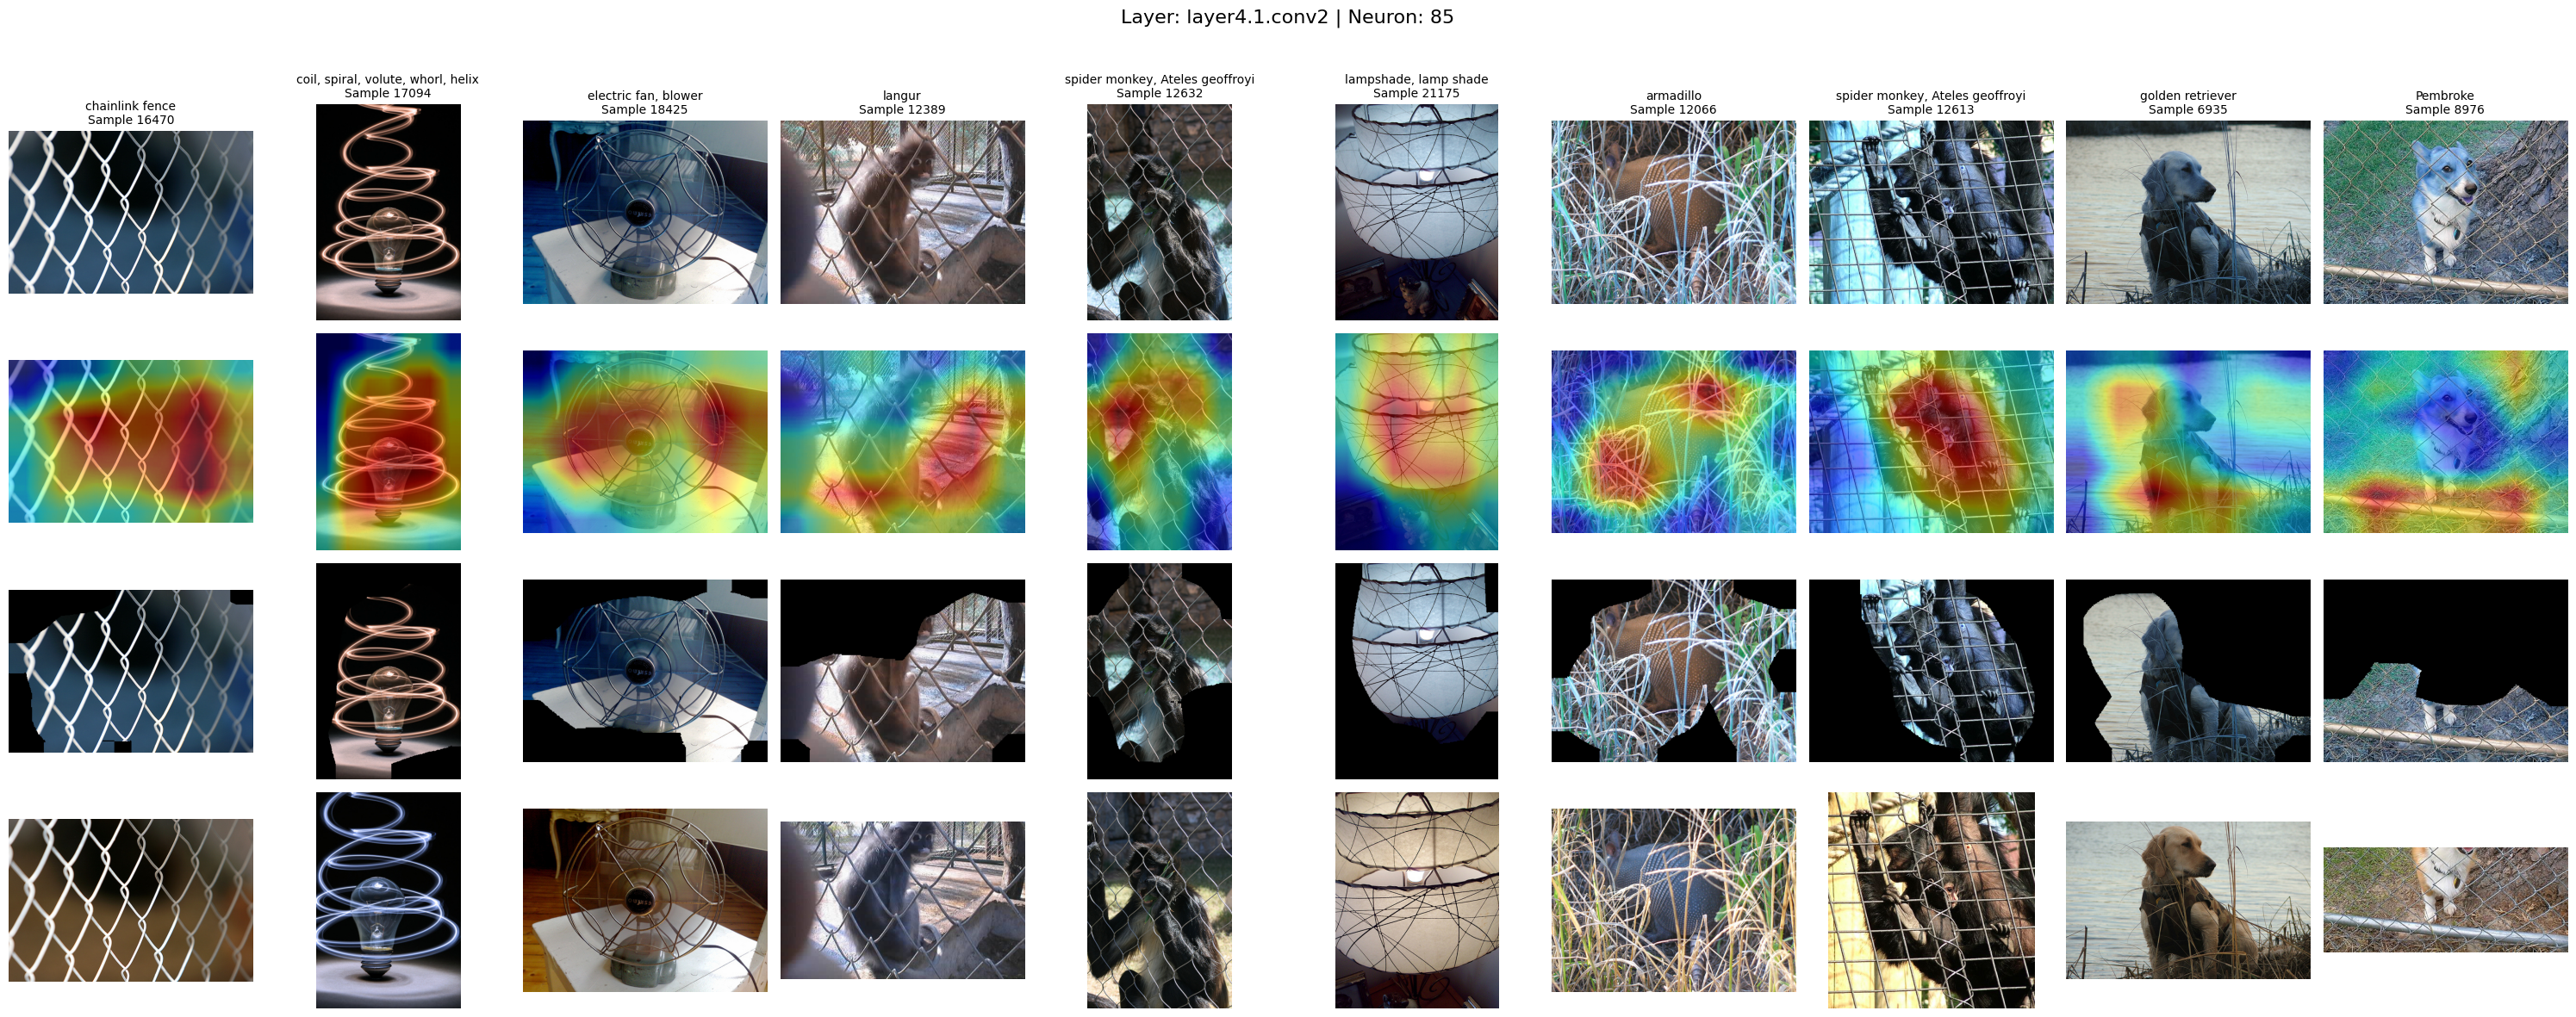

In [26]:
%reload_ext autoreload

import json
from interpretability.visualizations.visualization_functions import visualize_neuron
from datasets.imagenet_mini import ImagenetMini
from safetensors import safe_open
from semanticlens.component_visualization.activation_based import CustomActivationComponentVisualizer
from semanticlens.component_visualization.aggregators import aggregate_conv_mean

model_name = "resnet-50"
layer = "layer4.1.conv2"

model.name = model_name

dataset = ImagenetMini(
    wordnet_ids_to_classes_path="../datasets/input_files/wordnet_ids_to_classes.txt"
)
dataset.name = "imagenetmini-1000"
polysem_score_resnet_50_path = "../outputs/polysemanticity_scores/CLIP_Mobile_10_ref_samples/polysemanticity_score_resnet_50.json"
polysem_score_resnet_50 = json.load(open(polysem_score_resnet_50_path, "r"))

cv_obj = CustomActivationComponentVisualizer(
    model=model,
    dataset_model=dataset,
    dataset_fm=dataset,
    layer_names=[layer],
    num_samples=10,
    device="cpu",
    aggregate_fn= aggregate_conv_mean,
    cache_dir="../outputs/semanticlens_cache",
    model_name="resnet_50",
)

cv_obj.run()
cv_obj.create_crop_db()

visualize_neuron(
    cv_object=cv_obj,
    dataset=dataset,
    polysem_scores_model=polysem_score_resnet_50,
    layer="layer4.1.conv2",
    neuron_id=85,
    print_info=True
)